# Python codes for PCA analysis
PCA analysis for identifying putative batch effects across animal samples and characterize age correlations with PC values.

In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import os
import re
import anndata as ad
import pandas as pd
import random
import math
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import platform
import subprocess

In [2]:
print(f"Python Version: {platform.python_version()}")
print(f"Python Executable: {sys.executable}\n")
print("--- Installed Packages ---")

# Runs pip list using the active kernel's Python executable
result = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True)
print(result.stdout)

Python Version: 3.11.4
Python Executable: /home/wyang114/.conda/envs/TACCO_env/bin/python

--- Installed Packages ---
Package            Version
------------------ ---------
adjustText         0.8
anndata            0.10.7
argcomplete        1.12.0
array_api_compat   1.6
asttokens          2.4.1
biomart            0.9.2
Brotli             1.0.9
cached-property    1.5.2
certifi            2024.8.30
charset-normalizer 3.2.0
click              8.1.7
colorama           0.4.6
comm               0.2.2
contourpy          1.1.0
cycler             0.11.0
debugpy            1.8.1
decorator          5.1.1
exceptiongroup     1.2.2
executing          2.0.1
fonttools          4.41.1
h5py               3.9.0
idna               3.4
igraph             0.10.8
importlib-metadata 6.8.0
ipykernel          6.29.2
ipython            8.29.0
jedi               0.19.1
joblib             1.3.0
jupyter_client     8.6.0
jupyter_core       5.7.2
kiwisolver         1.4.4
leidenalg          0.10.1
llvmlite           

## region-specific PCA on age trajectory

(54, 29060)


/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


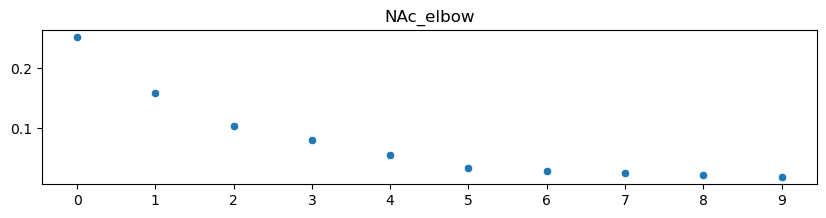

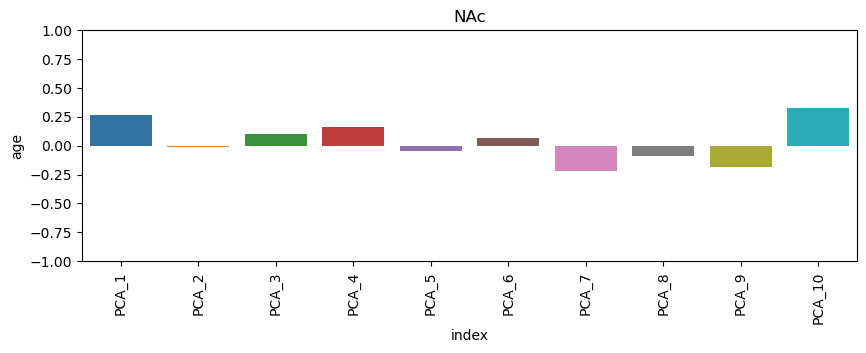

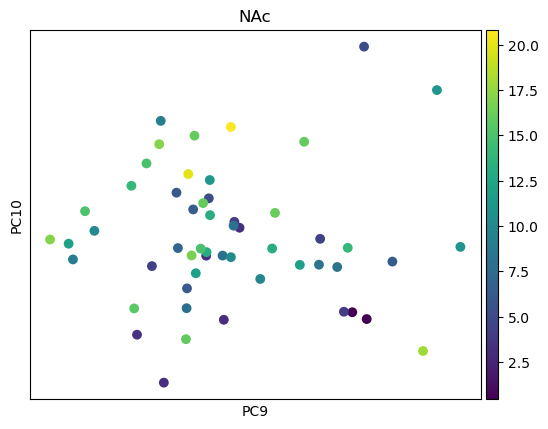

/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


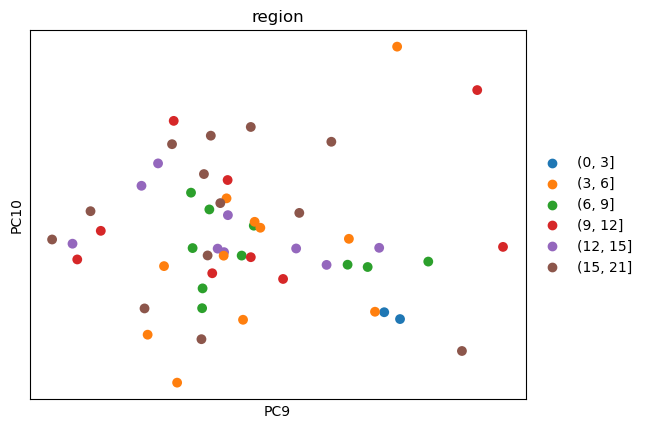

(54, 29060)


/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


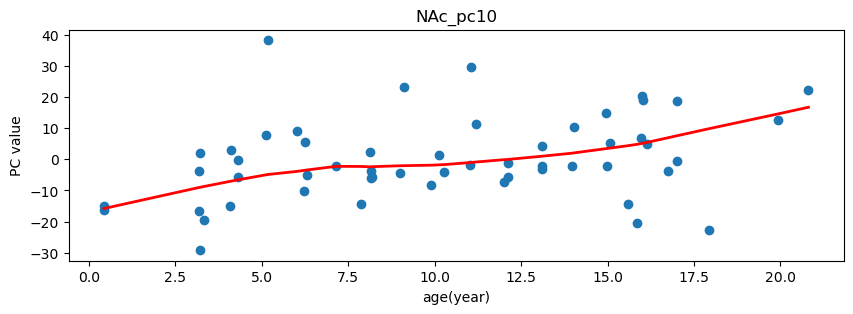

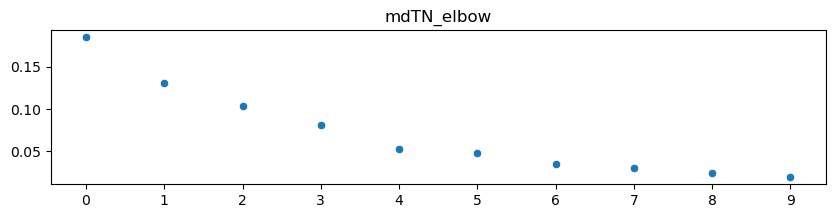

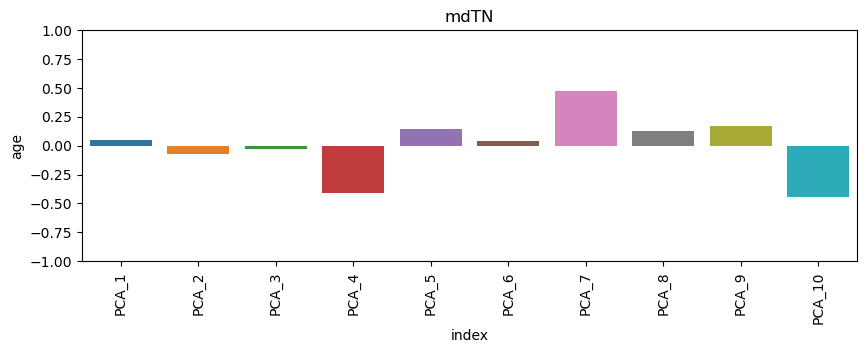

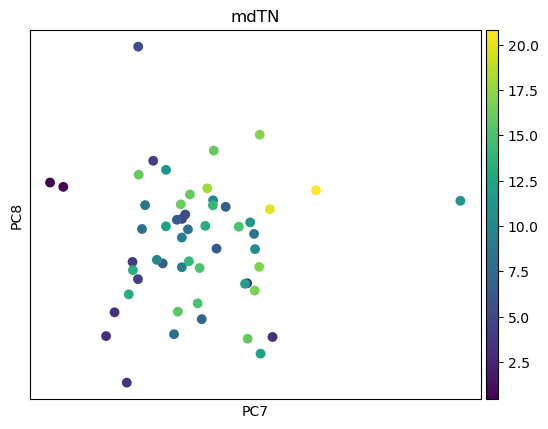

/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


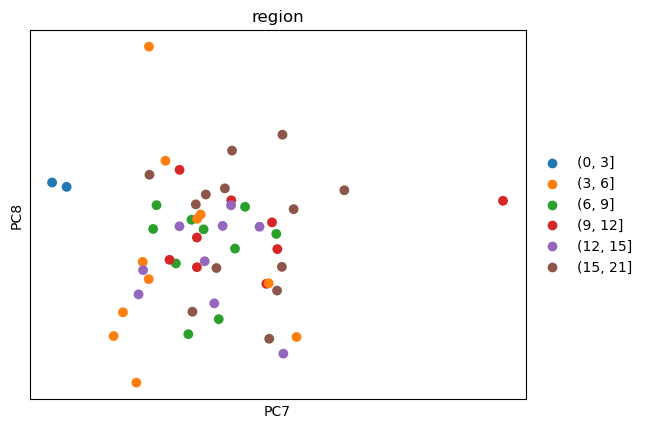

(49, 29060)


/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


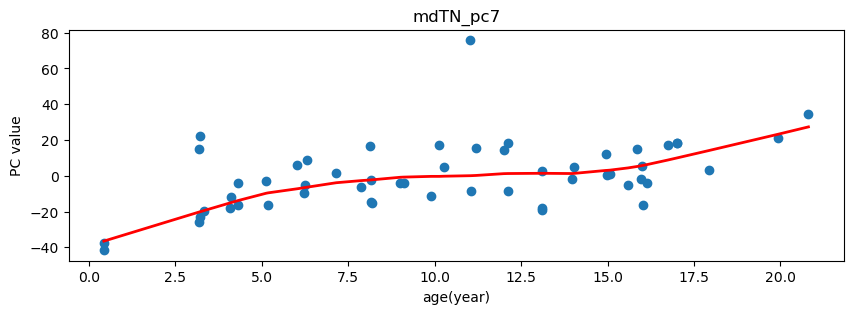

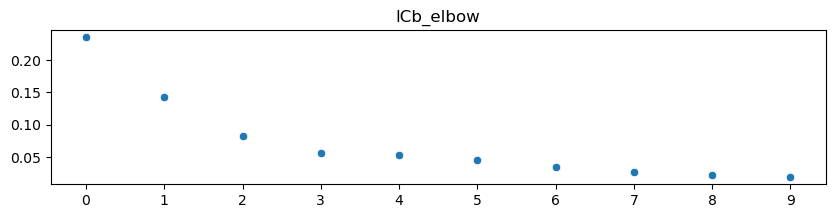

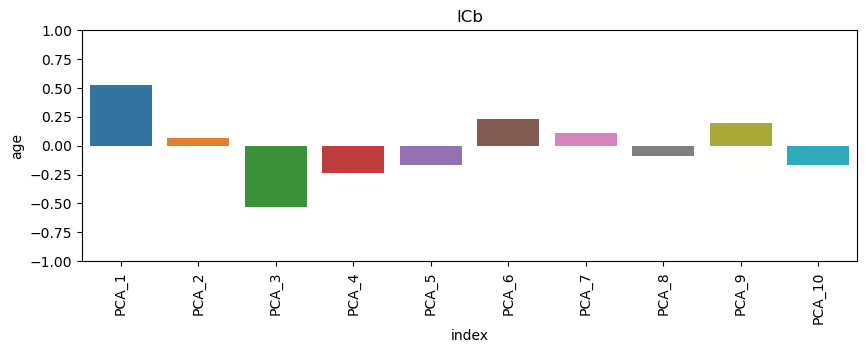

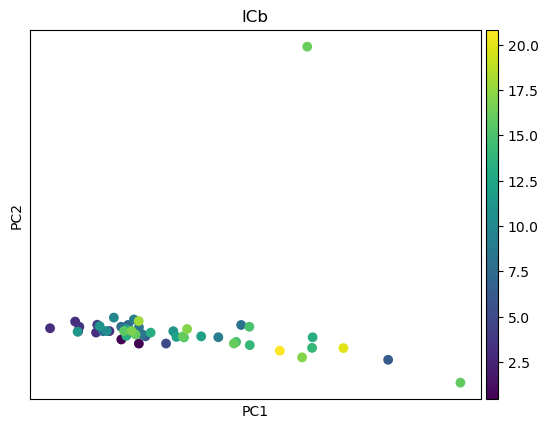

/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


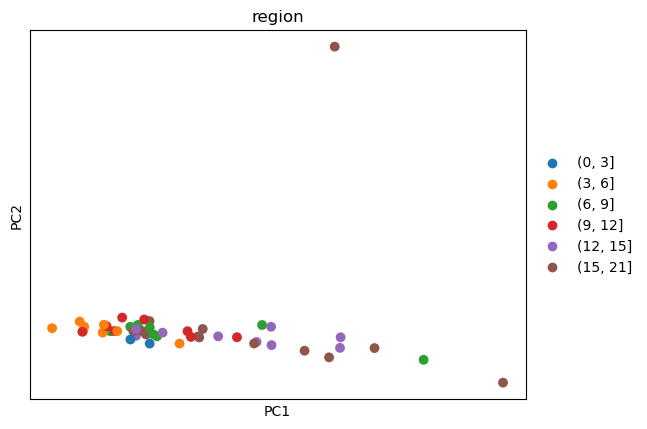

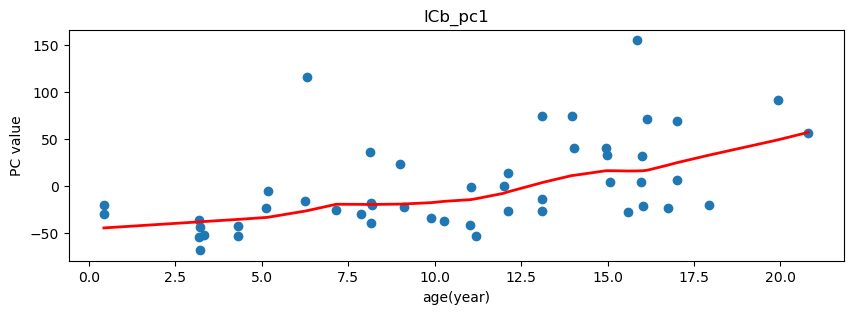

In [5]:
from statsmodels.nonparametric.smoothers_lowess import lowess
regions = ['NAc','mdTN','lCb']
npcs = 10

for region in regions:
    npcs = 10
    adata= sc.read_h5ad(f'/scratch/nsnyderm/u01/intermediate_files/regions_h5ad_update/{region}.h5ad')
    X=adata.raw.X
    one_hot_sample = pd.get_dummies(adata.obs['sample_id']).values.astype(int)
    bins = [0,3,6,9,12,15,21]
    adata.obs['age_group'] = pd.cut(adata.obs['age'], bins)
    pb_sample_mat = X.T.dot(one_hot_sample).T
    print(pb_sample_mat.shape)
    #Create a pseudobulk adata of age
    pb_meta = pd.DataFrame(adata.obs.groupby(['sample_id','region','sex','age','age_group']).size().rename('NCells')).reset_index()
    pb_meta = pb_meta.query('NCells>0')
    pb_adata = ad.AnnData(pb_sample_mat,obs = pb_meta, var = adata.raw.var)
    #pb_adata.write_h5ad('/scratch/wyang114/outputs/pseudobulk/all_sample_pb_adata.h5ad')
    
    sc.pp.normalize_total(pb_adata, target_sum=1e4)
    sc.pp.log1p(pb_adata),
    sc.pp.highly_variable_genes(pb_adata, n_top_genes=10000) #hvg
    pb_adata = pb_adata[:, pb_adata.var.highly_variable]
    #sc.pp.regress_out(pb_adata, keys='n_umi',n_jobs=20)  #optional
    sc.pp.scale(pb_adata, max_value=10)
    sc.tl.pca(pb_adata, n_comps=npcs)

    #elbow
    fig,ax=plt.subplots(1,1,figsize=(10,2))
    sns.scatterplot(pb_adata.uns['pca']['variance_ratio'],ax=ax)
    ax.set_xticks(ticks=np.arange(0,npcs,1));
    plt.title(f'{region}_elbow')
    plt.savefig(f'./figures/elbow_{region}_pcs.pdf',bbox_inches='tight')

    #correlation
    df_cor = pd.DataFrame(pb_adata.obsm['X_pca'],columns=['PCA_'+str(i+1) for i in range(npcs)])
    df_cor.index = df_cor.index.astype('str')
    df_cor['age']=pb_adata.obs['age'].tolist()
    correlations = pd.DataFrame(df_cor.corr()['age']).reset_index()
    fig,ax=plt.subplots(1,1,figsize=(10,3))
    sns.barplot(x='index', y='age', data=correlations.iloc[:npcs,:],ax=ax)
    plt.xticks(rotation=90);
    plt.ylim(-1,1)
    plt.title(region)
    plt.savefig(f'./figures/cor_{region}_pcs.pdf',bbox_inches='tight')

    #pca
    pc=abs(correlations.iloc[:npcs,1]).idxmax()+1
    if pc<10:
        up,low=pc, pc+1
    else:
        up,low=pc-1,pc
    sc.pl.pca(pb_adata,color='age',
              components=f'{up},{low}',
              size=200,title=region,
             save=f'_{region}_pc{pc}_age.pdf')
    sc.pl.pca(pb_adata,color='age_group',
          components=f'{up},{low}',
          size=200,title='region',
         save=f'_{region}_pc{pc}_age_group.pdf')

    #age trends
    fig,ax=plt.subplots(1,1,figsize=(10,3))
    x=df_cor['age']
    if(correlations.iloc[pc-1,1]<0):
        y=-df_cor[f'PCA_{pc}']
    else:
        y=df_cor[f'PCA_{pc}']
    plt.scatter(x,y)
    plt.title(f'{region}_pc{pc}')
    plt.xlabel('age(year)')
    plt.ylabel('PC value')
    # Apply LOESS smoothing
    loess_smoothed = lowess(y, x, frac=0.5)  # Adjust frac for smoothness
    x_smooth, y_smooth = loess_smoothed[:, 0], loess_smoothed[:, 1]
    plt.plot(x_smooth, y_smooth, color='red', label="LOESS Fit", linewidth=2)
    plt.savefig(f'./figures/scatter_{region}_pc{pc}.pdf',bbox_inches='tight')
    